# 01. 허스트 지수 (R/S 분석)

- 원본(2025-2 투자공학 과제)은 13개 자산의 월간·주간 로그수익률로 R/S 허스트 지수를 구하고, 수익률을 **한 번** 섞은 값(Scrambled)과 비교했다.
- 여기서는 같은 R/S 계산을 그대로 재현한 뒤, 섞기를 **500번** 반복해 귀무분포(기억 없음)를 만들고 p값으로 판단한다.
- 데이터: Yahoo Finance 종가(원본 과제에서 받은 CSV), 2024-12까지.

In [1]:
import sys, yaml
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager
for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = f; break
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
CFG = yaml.safe_load(open(ROOT / "configs/base.yaml"))
RES = ROOT / "results"; (RES / "figures").mkdir(parents=True, exist_ok=True)
from market_memory.hurst import hurst_test, log_returns, rs_hurst
H = CFG["hurst"]
def load(name, unit):
    return pd.read_csv(ROOT / H["data_dir"] / f"{name}_{unit}.csv")["Close"]

## 1. 원본 값 재현 (Unscrambled)

In [2]:
ORIG = {
    ("1wk", "S&P 500"): (0.5547, 0.4918), ("1wk", "NASDAQ"): (0.5763, 0.5211), ("1wk", "Apple"): (0.5506, 0.5923),
    ("1wk", "Bitcoin"): (0.6553, 0.6016), ("1wk", "KOSPI"): (0.5495, 0.5254), ("1wk", "Samsung"): (0.5178, 0.5458),
    ("1wk", "Google"): (0.5399, 0.6052), ("1wk", "Intel"): (0.5266, 0.5144), ("1wk", "cocacola"): (0.4994, 0.5222),
    ("1wk", "nvdia"): (0.5611, 0.5790), ("1wk", "tesla"): (0.5990, 0.5901), ("1wk", "sk hynix"): (0.5336, 0.5661),
    ("1wk", "eth"): (0.6655, 0.5291),
    ("1mo", "S&P 500"): (0.6102, 0.6159), ("1mo", "NASDAQ"): (0.6122, 0.5124), ("1mo", "Apple"): (0.5604, 0.5762),
    ("1mo", "Bitcoin"): (0.7886, 0.6156), ("1mo", "KOSPI"): (0.5765, 0.5977), ("1mo", "Samsung"): (0.5198, 0.5465),
    ("1mo", "Google"): (0.5674, 0.5819), ("1mo", "Intel"): (0.5196, 0.5119), ("1mo", "cocacola"): (0.5245, 0.5313),
    ("1mo", "nvdia"): (0.5705, 0.6883), ("1mo", "tesla"): (0.7061, 0.5131), ("1mo", "sk hynix"): (0.5320, 0.5876),
    ("1mo", "eth"): (0.7653, 0.6983),
}
rep = pd.DataFrame([{"주기": u, "자산": a, "원본 H": h, "재계산 H": rs_hurst(log_returns(load(a, u))), "원본 Scrambled(1회)": s}
                    for (u, a), (h, s) in ORIG.items()])
rep["차이"] = rep["재계산 H"] - rep["원본 H"]
print("최대 |차이|:", rep["차이"].abs().max().round(5))
rep.round(4)

최대 |차이|: 0.02554


,주기,자산,원본 H,재계산 H,원본 Scrambled(1회),차이
0,1wk,S&P 500,0.5547,0.5547,0.4918,0.0000
1,1wk,NASDAQ,0.5763,0.5763,0.5211,0.0000
2,1wk,Apple,0.5506,0.5506,0.5923,0.0000
3,1wk,Bitcoin,0.6553,0.6553,0.6016,0.0000
4,1wk,KOSPI,0.5495,0.5495,0.5254,-0.0000
5,1wk,Samsung,0.5178,0.5178,0.5458,-0.0000
6,1wk,Google,0.5399,0.5399,0.6052,-0.0000
7,1wk,Intel,0.5266,0.5266,0.5144,-0.0000
8,1wk,cocacola,0.4994,0.4994,0.5222,-0.0000
9,1wk,nvdia,0.5611,0.5611,0.5790,0.0000


## 2. 섞기 500회 귀무분포와 비교

In [3]:
rows = []
for u in H["units"]:
    for a in H["assets"]:
        r = hurst_test(load(a, u), n_shuffles=H["n_shuffles"], seed=H["seed"])
        rows.append({"주기": u, "자산": a, **{k: v for k, v in r.items()}})
tab = pd.DataFrame(rows)
tab["유의(5%)"] = tab["p_value"] < 0.05
tab.to_csv(RES / "hurst_table.csv", index=False)
tab.round(4)

,주기,자산,n_returns,H,null_mean,null_std,null_lo,null_hi,excess,p_value,유의(5%)
0,1d,S&P 500,11343,0.5400,0.5373,0.0197,0.4965,0.5765,0.0027,0.4651,False
1,1d,NASDAQ,11343,0.5748,0.5383,0.0201,0.4986,0.5799,0.0365,0.0359,True
2,1d,KOSPI,6910,0.5466,0.5418,0.0211,0.5003,0.5836,0.0048,0.4112,False
3,1d,Apple,11103,0.5386,0.5368,0.0181,0.5020,0.5709,0.0018,0.4631,False
4,1d,Google,5125,0.5217,0.5410,0.0212,0.5002,0.5795,-0.0193,0.8084,False
5,1d,Intel,11291,0.5222,0.5368,0.0190,0.5038,0.5738,-0.0146,0.7705,False
6,1d,cocacola,11343,0.4954,0.5371,0.0188,0.4983,0.5727,-0.0417,0.9760,False
7,1d,nvdia,6526,0.5460,0.5402,0.0202,0.5006,0.5773,0.0057,0.3932,False
8,1d,tesla,3650,0.5772,0.5459,0.0249,0.4974,0.5913,0.0314,0.1058,False
9,1d,Samsung,6260,0.5199,0.5420,0.0229,0.4988,0.5826,-0.0220,0.8323,False


## 3. 원본의 1회 Scrambled 값은 귀무분포 안 어디에 있었나

In [4]:
chk = rep.merge(tab[["주기", "자산", "null_mean", "null_lo", "null_hi"]], on=["주기", "자산"])
chk["1회 값이 95% 구간 안"] = chk["원본 Scrambled(1회)"].between(chk["null_lo"], chk["null_hi"])
print("원본 1회 Scrambled 값 중 95% 구간 안:", int(chk["1회 값이 95% 구간 안"].sum()), "/", len(chk))
print("원본에서 'Unscrambled > Scrambled' 였던 경우:", int((chk["원본 H"] > chk["원본 Scrambled(1회)"]).sum()), "/", len(chk))
chk[["주기", "자산", "원본 H", "원본 Scrambled(1회)", "null_mean", "null_lo", "null_hi"]].round(4)

원본 1회 Scrambled 값 중 95% 구간 안: 25 / 26
원본에서 'Unscrambled > Scrambled' 였던 경우: 12 / 26


,주기,자산,원본 H,원본 Scrambled(1회),null_mean,null_lo,null_hi
0,1wk,S&P 500,0.5547,0.4918,0.5477,0.4915,0.5985
1,1wk,NASDAQ,0.5763,0.5211,0.5475,0.4912,0.6011
2,1wk,Apple,0.5506,0.5923,0.5488,0.4954,0.6059
3,1wk,Bitcoin,0.6553,0.6016,0.5625,0.4760,0.6485
4,1wk,KOSPI,0.5495,0.5254,0.5521,0.4903,0.6179
5,1wk,Samsung,0.5178,0.5458,0.5518,0.4869,0.6188
6,1wk,Google,0.5399,0.6052,0.5565,0.4842,0.6178
7,1wk,Intel,0.5266,0.5144,0.5467,0.4904,0.6014
8,1wk,cocacola,0.4994,0.5222,0.5465,0.4917,0.6001
9,1wk,nvdia,0.5611,0.5790,0.5522,0.4936,0.6162


## 4. 요약표

In [5]:
piv = tab.pivot(index="자산", columns="주기", values=["H", "null_mean", "p_value"]).reindex(H["assets"])
lines = ["| 자산 | " + " | ".join(f"{u} H (귀무 평균, p)" for u in H["units"]) + " |", "|---|" + "---|" * len(H["units"])]
for a in H["assets"]:
    cells = []
    for u in H["units"]:
        h, m, p = piv.loc[a, ("H", u)], piv.loc[a, ("null_mean", u)], piv.loc[a, ("p_value", u)]
        cells.append(f"{h:.3f} ({m:.3f}, {p:.3f}){' *' if p < 0.05 else ''}")
    lines.append(f"| {a} | " + " | ".join(cells) + " |")
md_t = "\n".join(lines)
(RES / "hurst_summary.md").write_text(md_t + "\n")
print(md_t)
print()
print(tab.groupby("주기")[["H", "null_mean"]].mean().round(4))
print(tab.groupby("주기")["유의(5%)"].sum())

| 자산 | 1d H (귀무 평균, p) | 1wk H (귀무 평균, p) | 1mo H (귀무 평균, p) |
|---|---|---|---|
| S&P 500 | 0.540 (0.537, 0.465) | 0.555 (0.548, 0.397) | 0.610 (0.565, 0.198) |
| NASDAQ | 0.575 (0.538, 0.036) * | 0.576 (0.548, 0.152) | 0.612 (0.562, 0.164) |
| KOSPI | 0.547 (0.542, 0.411) | 0.549 (0.552, 0.527) | 0.577 (0.569, 0.439) |
| Apple | 0.539 (0.537, 0.463) | 0.551 (0.549, 0.451) | 0.560 (0.560, 0.513) |
| Google | 0.522 (0.541, 0.808) | 0.540 (0.557, 0.689) | 0.567 (0.573, 0.547) |
| Intel | 0.522 (0.537, 0.770) | 0.527 (0.547, 0.768) | 0.520 (0.562, 0.806) |
| cocacola | 0.495 (0.537, 0.976) | 0.499 (0.546, 0.956) | 0.524 (0.567, 0.828) |
| nvdia | 0.546 (0.540, 0.393) | 0.561 (0.552, 0.371) | 0.571 (0.567, 0.485) |
| tesla | 0.577 (0.546, 0.106) | 0.599 (0.558, 0.158) | 0.706 (0.576, 0.044) * |
| Samsung | 0.520 (0.542, 0.832) | 0.518 (0.552, 0.846) | 0.520 (0.566, 0.770) |
| sk hynix | 0.550 (0.542, 0.347) | 0.559 (0.551, 0.391) | 0.558 (0.568, 0.597) |
| Bitcoin | 0.606 (0.547, 0.006) *

## 5. 그림

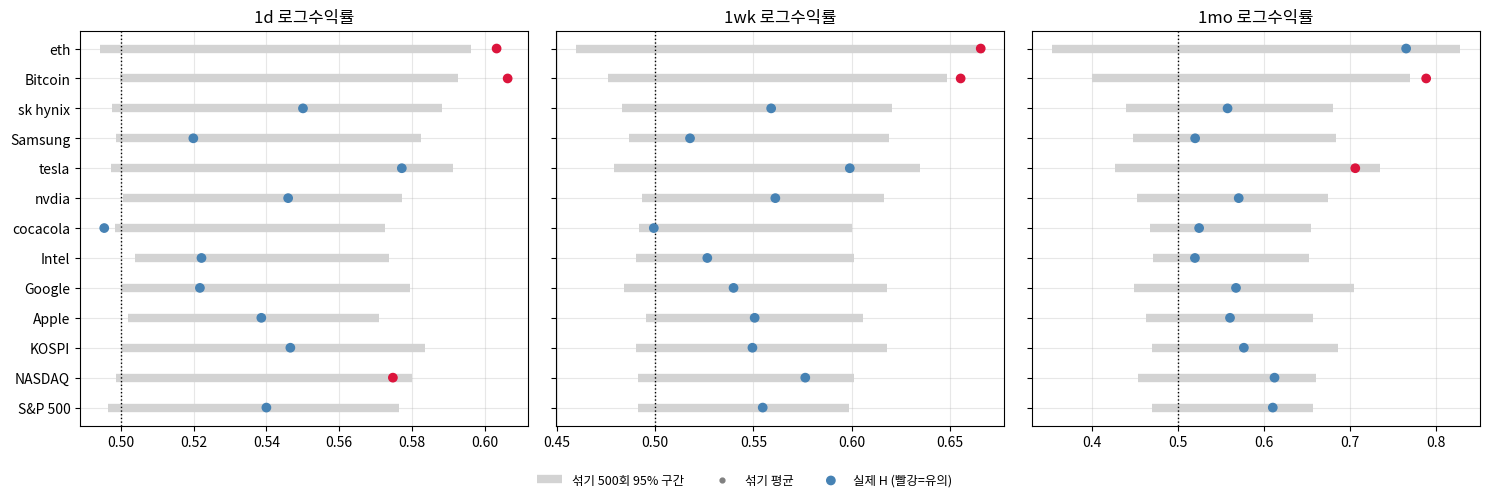

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, u in zip(axes, H["units"]):
    d = tab[tab["주기"] == u].set_index("자산").reindex(H["assets"])
    y = np.arange(len(d))
    ax.hlines(y, d["null_lo"], d["null_hi"], color="lightgray", lw=6, label="섞기 500회 95% 구간")
    ax.scatter(d["null_mean"], y, color="gray", s=12, label="섞기 평균")
    ax.scatter(d["H"], y, color=np.where(d["p_value"] < 0.05, "crimson", "steelblue"), zorder=3, label="실제 H (빨강=유의)")
    ax.axvline(0.5, color="k", ls=":", lw=1)
    ax.set_yticks(y); ax.set_yticklabels(d.index); ax.set_title(f"{u} 로그수익률"); ax.grid(alpha=.3)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.savefig(RES / "figures/hurst_null.png", dpi=150); plt.show()